# Task 2 — Learning a visual interface

SigLIP–Qwen3-0.6B, a trainable connector, and a three-stage curriculum. The required 196-token experiment is complete.

**Default: CPU report mode.** Run all cells to audit the saved records and display the results. This does not load model weights or perform inference. GPU reproduction is an explicit opt-in at the end. Original weights, images, feature arrays and tensor checkpoints remain in the Drive experiment folder; the repository contains code and recorded evidence.

Author: Abdullah Irfan · ATML PA3 · Seed 6304

In [1]:
from pathlib import Path
import os, sys, json, subprocess
from IPython.display import display, Markdown, Image

# Run from the repository's task2 folder, or from Colab with the existing Drive experiment.
if Path('/content').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

override = os.environ.get('PA3_TASK2_REPORT_DIR')
candidates = ([Path(override)] if override else []) + [
    Path.cwd(), Path.cwd() / 'task2',
    Path('/content/drive/MyDrive/ATML/PA3/pa3_repo/task2'),
    Path('/content/drive/MyDrive/ATML/PA3/task2'),
]
TASK2 = next((p for p in candidates if (p / 'analysis/audit.json').is_file()), None)
assert TASK2 is not None, 'Set PA3_TASK2_REPORT_DIR to the finalized task2 folder.'
print('Report folder:', TASK2)
print('Mode: CPU analysis of saved records')


Mounted at /content/drive
Report folder: /content/drive/MyDrive/ATML/PA3/pa3_repo/task2
Mode: CPU analysis of saved records


## Experimental setup

The frozen SigLIP encoder supplies 196 × 768 final patch features, normalized exactly once and cached in FP16. The connector is Linear(768,1024) → GELU → Linear(1024,1024), with 1,837,056 parameters. Its output scale was calibrated on 128 training images only and fixed at 0.05425837. Original Qwen weights remain frozen. Stages 2–3 add rank-16 attention LoRA (alpha 32, dropout 0.05), giving 6,424,576 total trainable parameters. Thinking is disabled.

| Stage | Updates | Connector peak LR | LoRA peak LR | Sampling |
| --- | ---: | ---: | ---: | --- |
| Caption alignment | 2250 | 1e-3 | — | Two passes over 18,000 captions |
| Visual instruction | 1500 | 1e-4 | 2e-5 | Presence 50%, counting 25%, captions 25% |
| Natural VQA | 750 | 5e-5 | 1e-5 | Natural 70%, presence/counting/captions 10% each |

Microbatch 8 × accumulation 2; 72,000 successful example presentations. Each stage uses fresh AdamW, weight decay 0.01, 5% warmup then cosine decay toward 10% of peak LR, global clipping 1.0, FP16 AMP with dynamic scaling, FP32 trainables and optimizer states, and gradient checkpointing. Loss averages response-plus-EOT tokens within examples, then examples within the effective batch. Five initial AMP overflows were retried on the same batch.

Code: `code/task2_vlm.py`, `code/task2_sampler.py`, `code/task2_train.py`; full recipe: `configs/training_recipe.json`.

In [2]:
recipe = json.loads((TASK2 / 'configs/training_recipe.json').read_text())
print(json.dumps(recipe, indent=2))

{
  "seed": 6304,
  "stages": {
    "1": {
      "updates": 2250,
      "connector_lr": 0.001,
      "adapter_lr": 0.0
    },
    "2": {
      "updates": 1500,
      "connector_lr": 0.0001,
      "adapter_lr": 2e-05
    },
    "3": {
      "updates": 750,
      "connector_lr": 5e-05,
      "adapter_lr": 1e-05
    }
  },
  "microbatch": 8,
  "accumulation": 2,
  "effective_batch": 16,
  "weight_decay": 0.01,
  "betas": [
    0.9,
    0.999
  ],
  "epsilon": 1e-08,
  "clip_norm": 1.0,
  "warmup_rule": "ceil(0.05 * stage updates); LambdaLR starts at zero",
  "cosine_final_fraction": 0.1,
  "optimizer_policy": "fresh AdamW/scheduler each stage; continue dynamic scaler; decay all trainable tensors including connector biases",
  "stage1_order": "two independently seeded permutations of the 18000 saved captions",
  "stage2_draw_probabilities": {
    "presence": 0.5,
    "counting": 0.25,
    "caption": 0.25
  },
  "stage3_draw_probabilities": {
    "natural": 0.7,
    "presence": 0.1,
    "co

## Data and isolation

Training uses 6000 train2014 images: three captions per image, reusable grounding pools, and 1536 natural complementary pairs. Development has 96 caption examples, 24 grounding pairs and 32 natural pairs. Final test has 64 grounding pairs and 96 natural pairs. All five evaluation image sets are mutually disjoint and excluded from training/replay. Natural pairs have different canonical answers with at least 8/10 annotator agreement per image. Selection IDs and the mismatched-image mapping were fixed before predictions.

Question content is capped at 80 tokens, captions at 64, and short-answer targets at 16; eligible examples were selected without truncating their original targets. Exact selection details are in `code/DATA_PREPARATION_README.md`.

In [3]:
selection = json.loads((TASK2 / 'results/data_selection.json').read_text())
for key in ['caption_train_examples', 'natural_pairs', 'grounding_pairs', 'evaluation_images_by_set', 'image_disjoint']:
    print(f'{key}: {selection[key]}')

caption_train_examples: 18000
natural_pairs: {'train': 1536, 'dev': 32, 'test': 96}
grounding_pairs: {'train': 8192, 'dev': 24, 'test': 64}
evaluation_images_by_set: {'captions_dev': 96, 'natural_dev': 64, 'natural_test': 192, 'grounding_dev': 48, 'grounding_test': 128}
image_disjoint: True


## Audit the saved run

This CPU command rechecks available source/split hashes, evaluation isolation, every seeded mixture draw, stage learning rates, development means, final reference/image mappings, exact and soft scores, and all 4000-resample pair-bootstrap intervals. It regenerates the tables and plots. Model and checkpoint tensors are not loaded. Their recorded hashes are retained, but the exported records alone cannot verify their bytes. Full-resolution qualitative panels are regenerated only when the original image archive manifest is available.

In [4]:
subprocess.run([sys.executable, str(TASK2 / 'code/task2_analyze.py'), '--task-dir', str(TASK2)], check=True)
audit = json.loads((TASK2 / 'analysis/audit.json').read_text())
assert audit['passed']
for check in audit['checks']:
    print('PASS:', check)

PASS: Training, smoke, final evaluation, source code, available inputs, and selected-split hashes agree.
PASS: Dataset sizes, original consensus targets, pair structure, natural type quotas, and all evaluation image isolation checks pass.
PASS: All 26 feature shard records cover the 6528 selected images exactly; FP16 and one final normalization are recorded.
PASS: 4500 successful updates, 72000 presentations, 18 checkpoint markers, every seeded mixture draw, and all stage learning rates verified.
PASS: All 12 development evaluations, per-example means, and image-swap penalty calculations verified.
PASS: All 1280 final predictions, references, image controls, exact/soft scores, EOS/cap flags, pair metrics, and 4000-resample paired intervals independently recomputed.


## Learning curves

Dashed boundaries mark updates 2250 and 3750. Loss changes at stage transitions reflect changing training mixtures as well as learning. Caption loss includes EOT; answer NLL excludes it. Positive swap penalty means the correct image makes the original reference more likely.

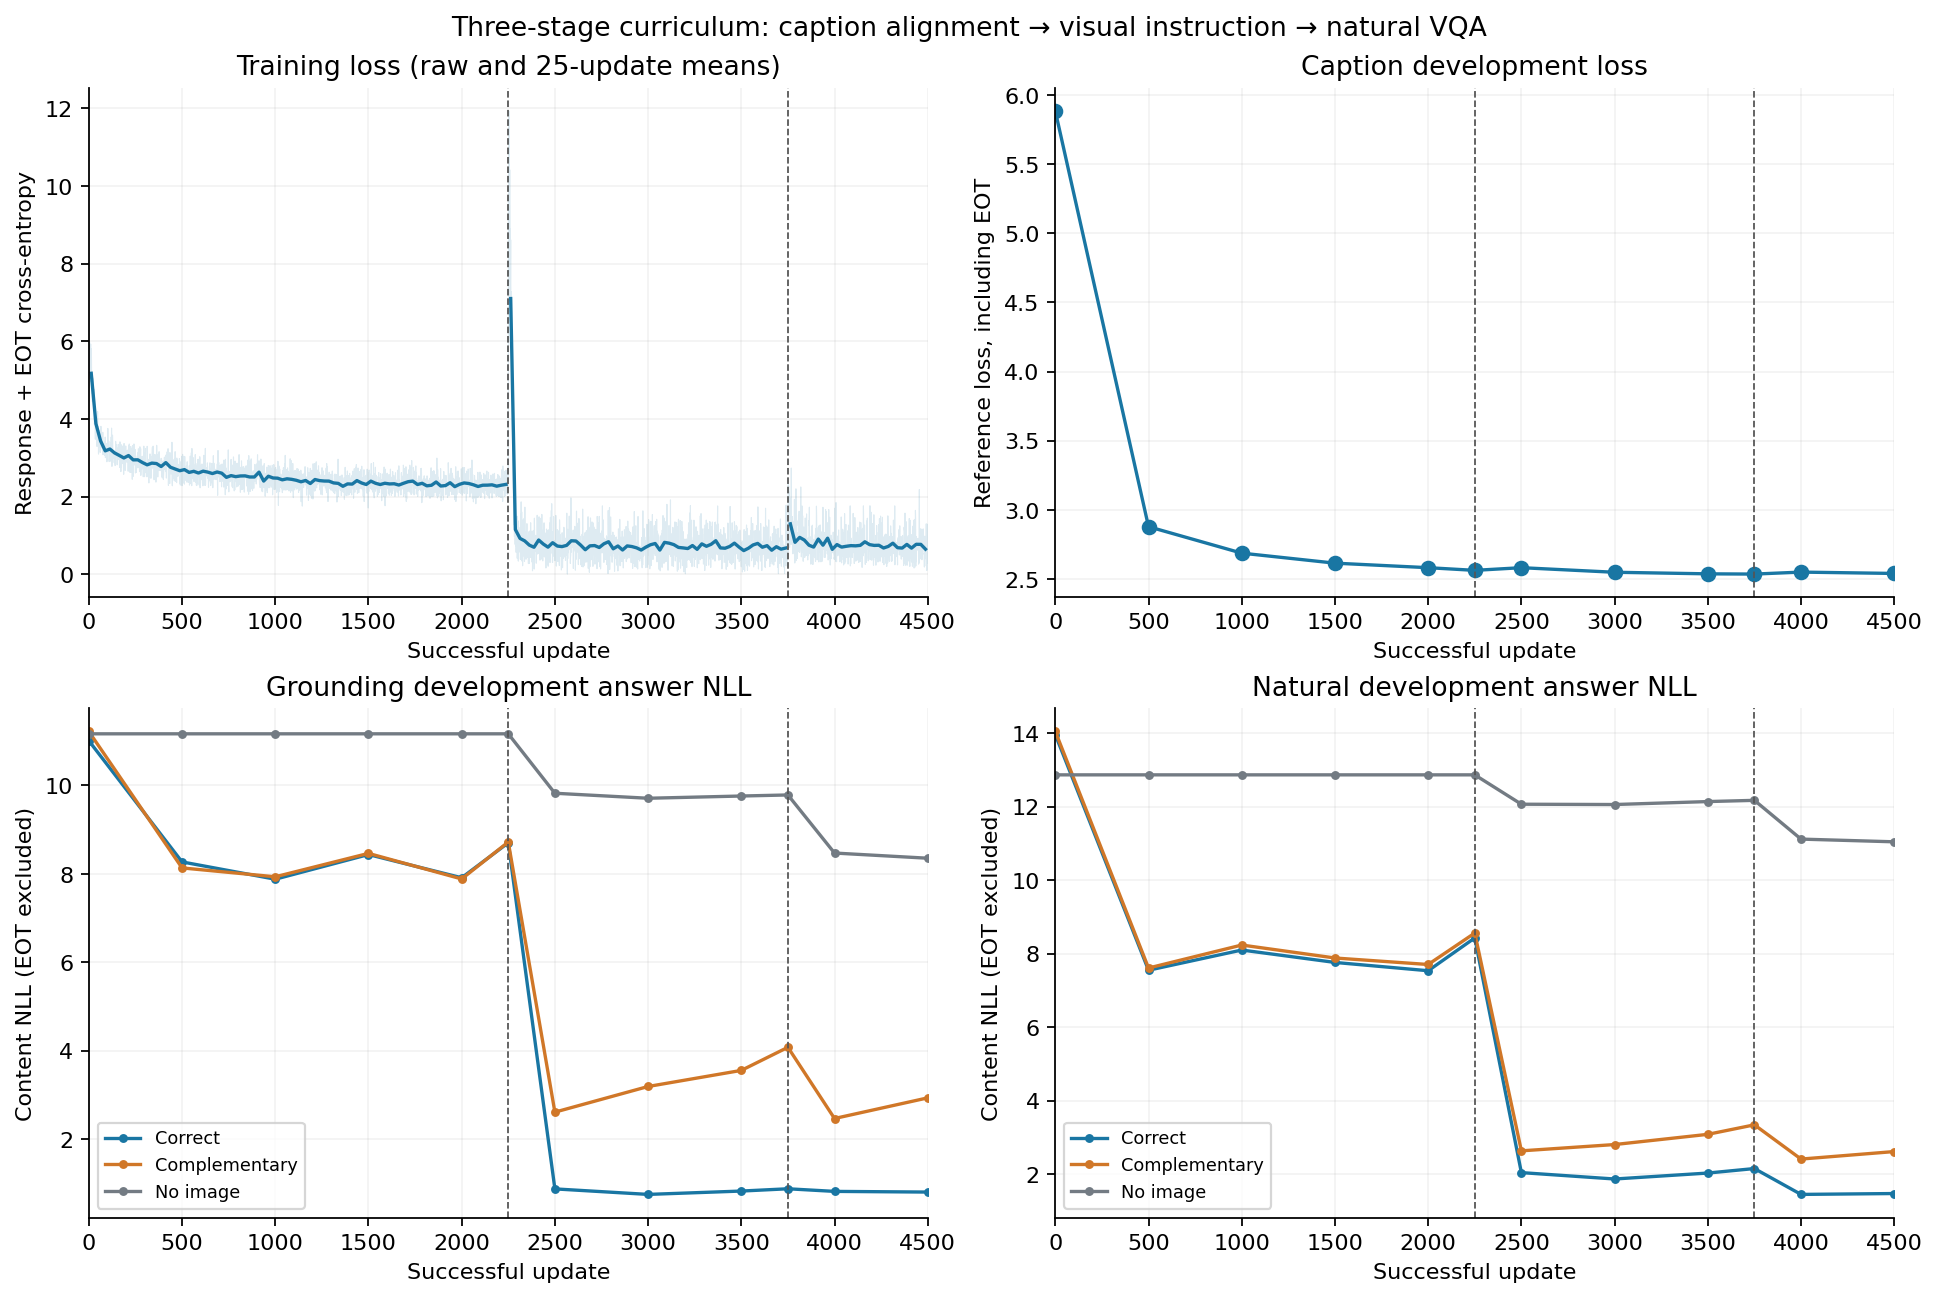

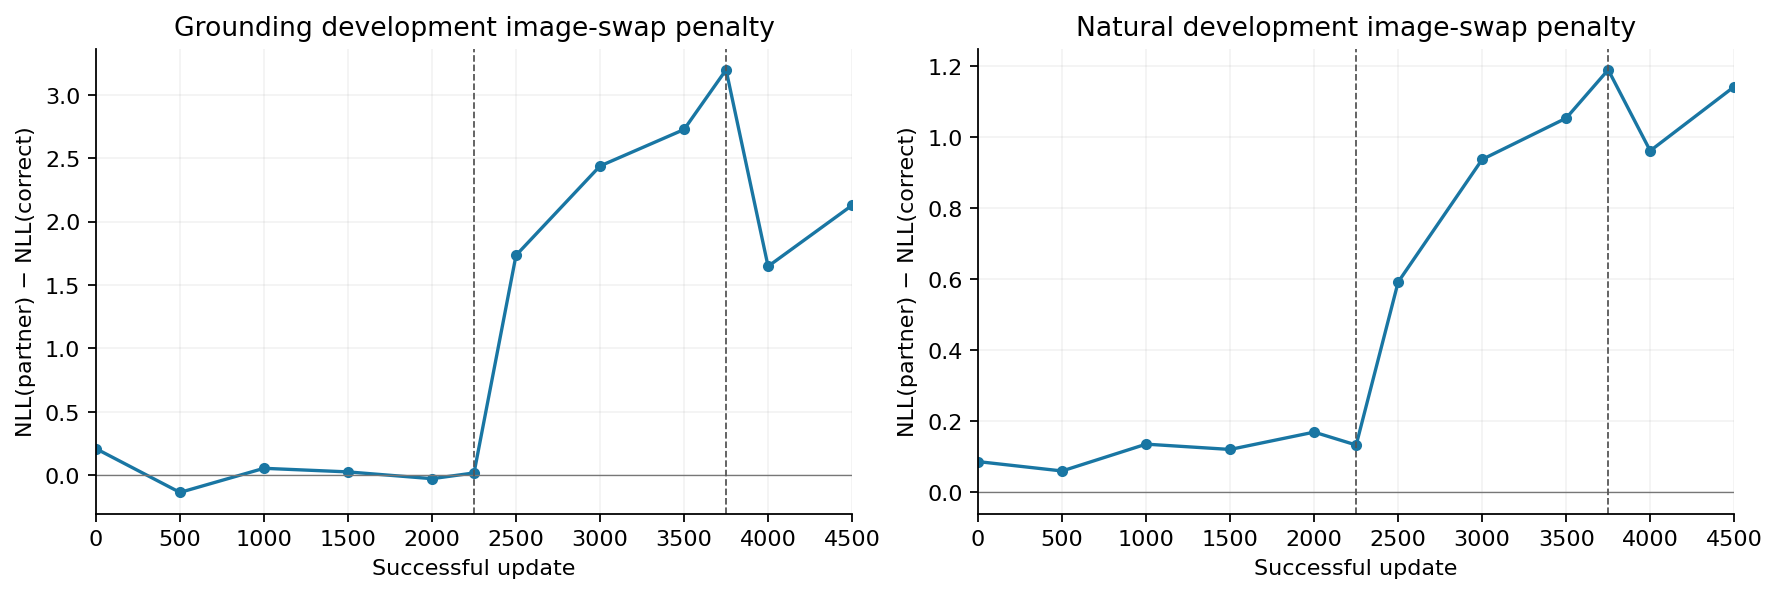

In [5]:
for name in ['learning_curves', 'image_swap_penalties']:
    display(Image(filename=str(TASK2 / 'figures' / f'{name}.png')))

## Final evaluation

Only the final Stage 3 model is used. Generation is greedy, thinking disabled, batch 8, maximum 16 new tokens. Correct, complementary, mismatched and no-image conditions retain the original questions and references. No-image inputs omit visual tokens and rebuild masks/positions.

Grounding uses normalized exact match. Natural VQA uses the mean leave-one-out consensus score over all ten human answers. Empty outputs remain in denominators. Bootstrap intervals use 4000 complete-pair resamples and shared pair indices across conditions. These are local subset scores, not full-benchmark server results.

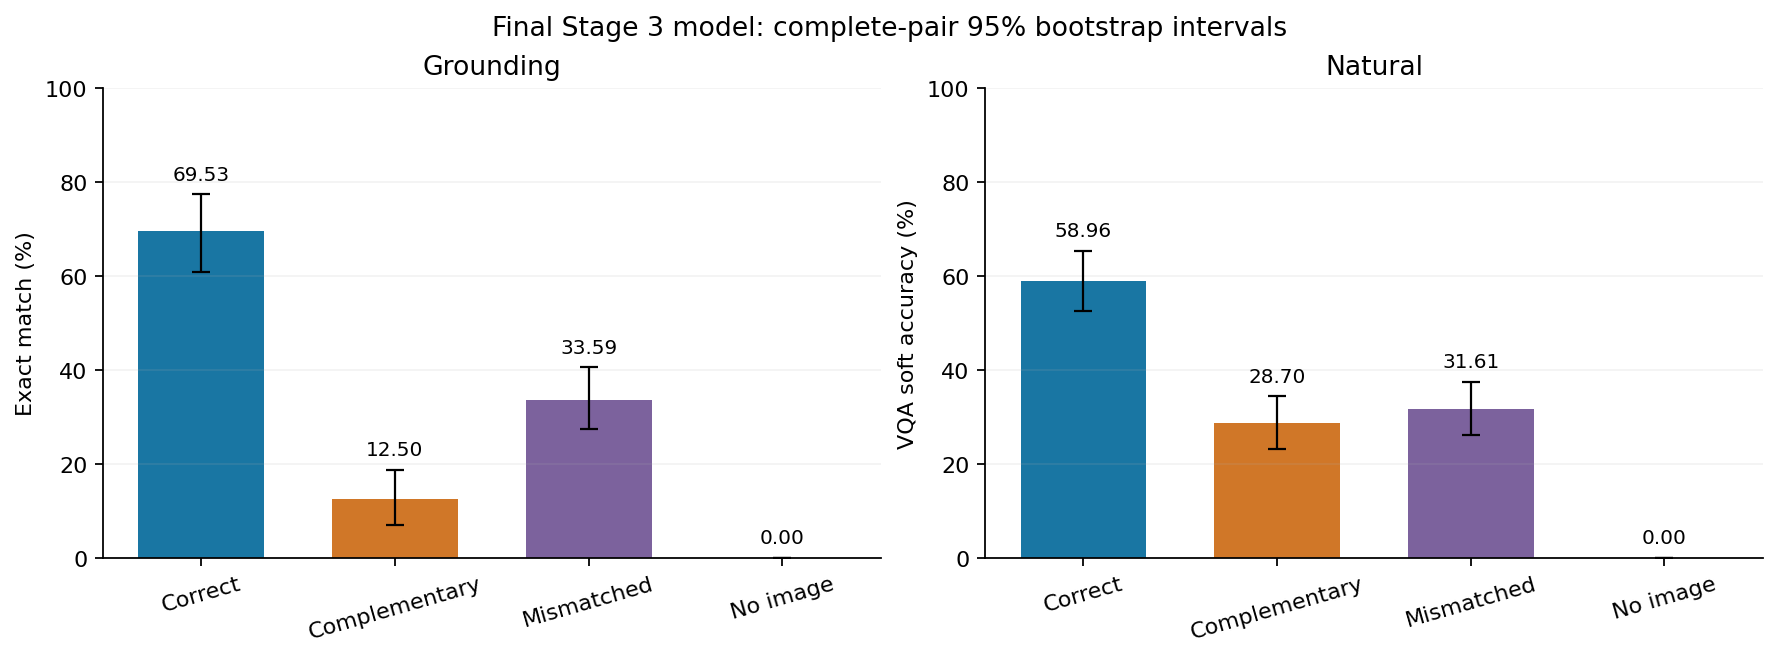

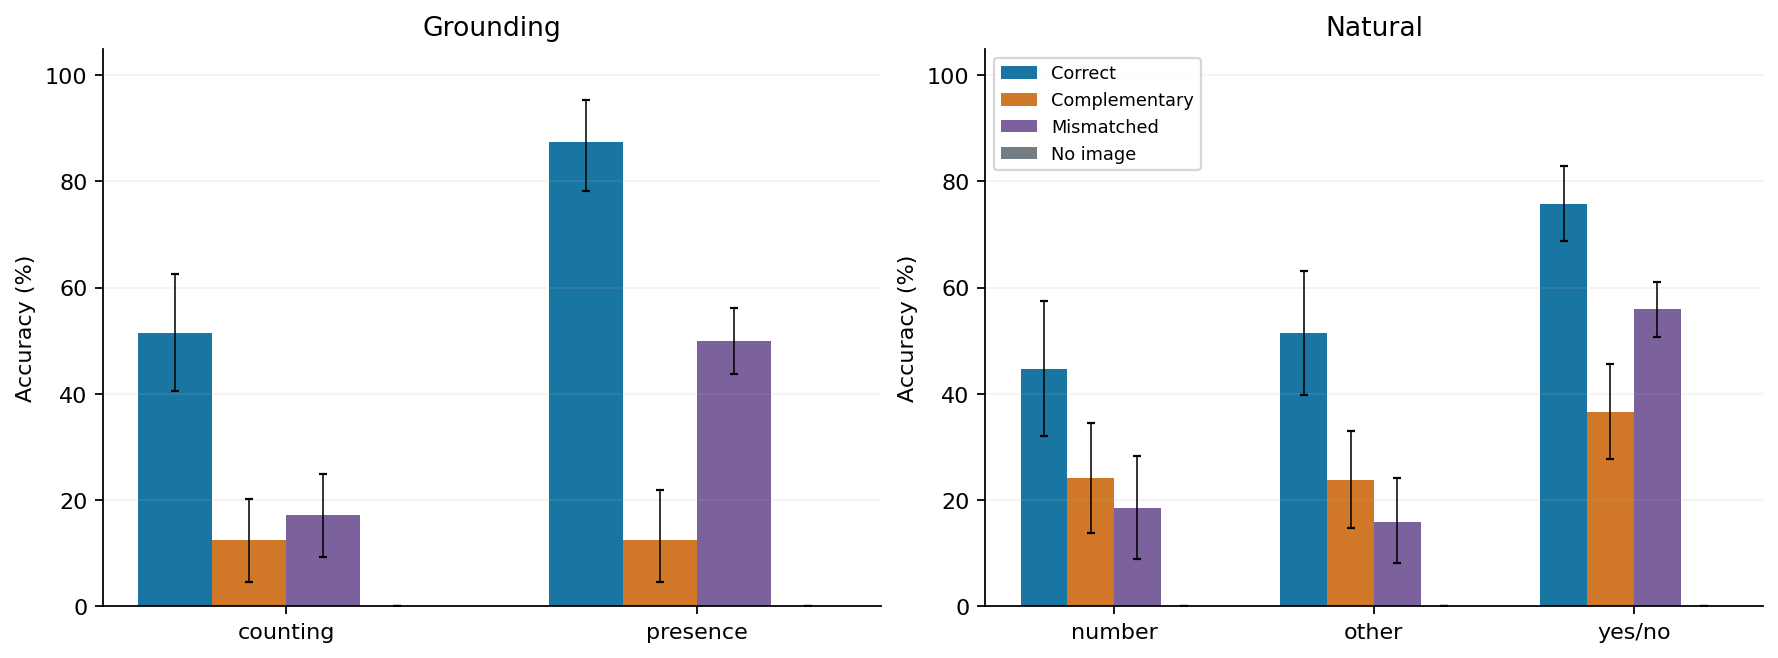

# Final results

Grounding uses normalized exact match; natural VQA uses the ten-answer leave-one-out soft score. Percentages are on a 0–100 scale. Intervals use 4000 complete-pair bootstrap resamples.

| Suite | Type | Image | Questions | Accuracy % [95% CI] | Pair accuracy % [95% CI] | Identical % [95% CI] | Empty % [95% CI] | Reference NLL [95% CI] | Generation ms/answer | Capped % |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| grounding | overall | Correct | 128 | 69.53 [60.94, 77.34] | 50.00 [37.50, 62.50] | 20.31 [10.94, 29.69] | 0.00 [0.00, 0.00] | 0.776 [0.601, 0.951] | 16.86 | 0.00 |
| grounding | overall | Complementary | 128 | 12.50 [7.03, 18.75] | 1.56 [0.00, 4.69] | 20.31 [10.94, 29.69] | 0.00 [0.00, 0.00] | 3.045 [2.654, 3.444] | 16.67 | 0.00 |
| grounding | overall | Mismatched | 128 | 33.59 [27.34, 40.62] | 3.12 [0.00, 7.81] | 84.38 [75.00, 92.19] | 0.00 [0.00, 0.00] | 2.022 [1.811, 2.236] | 16.55 | 0.00 |
| grounding | overall | No image | 128 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 8.333 [7.950, 8.700] | 108.51 | 39.06 |
| natural | overall | Correct | 192 | 58.96 [52.45, 65.42] | 28.12 [19.79, 37.50] | 52.08 [41.67, 61.46] | 0.00 [0.00, 0.00] | 1.423 [1.110, 1.782] | 27.13 | 1.04 |
| natural | overall | Complementary | 192 | 28.70 [23.28, 34.38] | 0.00 [0.00, 0.00] | 52.08 [41.67, 61.46] | 0.00 [0.00, 0.00] | 2.516 [2.122, 2.974] | 26.94 | 1.04 |
| natural | overall | Mismatched | 192 | 31.61 [26.20, 37.50] | 2.08 [0.00, 5.21] | 85.42 [78.12, 91.67] | 0.00 [0.00, 0.00] | 2.478 [2.096, 2.896] | 23.40 | 0.00 |
| natural | overall | No image | 192 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 10.663 [9.948, 11.402] | 123.75 | 59.38 |

## By question type

| Suite | Type | Image | Questions | Accuracy % [95% CI] | Pair accuracy % [95% CI] | Identical % [95% CI] | Empty % [95% CI] | Reference NLL [95% CI] | Generation ms/answer | Capped % |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| grounding | counting | Correct | 64 | 51.56 [40.62, 62.50] | 21.88 [9.38, 37.50] | 21.88 [9.38, 37.50] | 0.00 [0.00, 0.00] | 1.282 [1.079, 1.523] | 16.67 | 0.00 |
| grounding | counting | Complementary | 64 | 12.50 [4.69, 20.31] | 0.00 [0.00, 0.00] | 21.88 [9.38, 37.50] | 0.00 [0.00, 0.00] | 2.555 [2.103, 3.048] | 16.30 | 0.00 |
| grounding | counting | Mismatched | 64 | 17.19 [9.38, 25.00] | 0.00 [0.00, 0.00] | 81.25 [65.62, 93.75] | 0.00 [0.00, 0.00] | 2.224 [1.959, 2.493] | 16.53 | 0.00 |
| grounding | counting | No image | 64 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 7.458 [6.878, 8.072] | 124.24 | 78.12 |
| grounding | presence | Correct | 64 | 87.50 [78.12, 95.31] | 78.12 [62.50, 90.62] | 18.75 [6.25, 31.25] | 0.00 [0.00, 0.00] | 0.269 [0.136, 0.424] | 17.04 | 0.00 |
| grounding | presence | Complementary | 64 | 12.50 [4.69, 21.88] | 3.12 [0.00, 9.38] | 18.75 [6.25, 31.25] | 0.00 [0.00, 0.00] | 3.535 [2.974, 4.122] | 17.04 | 0.00 |
| grounding | presence | Mismatched | 64 | 50.00 [43.75, 56.25] | 6.25 [0.00, 15.62] | 87.50 [75.00, 96.88] | 0.00 [0.00, 0.00] | 1.820 [1.503, 2.128] | 16.58 | 0.00 |
| grounding | presence | No image | 64 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 9.207 [9.012, 9.413] | 92.79 | 0.00 |
| natural | number | Correct | 48 | 44.79 [32.08, 57.50] | 16.67 [4.17, 33.33] | 41.67 [20.83, 62.50] | 0.00 [0.00, 0.00] | 1.322 [1.002, 1.645] | 26.18 | 0.00 |
| natural | number | Complementary | 48 | 24.17 [13.75, 34.58] | 0.00 [0.00, 0.00] | 41.67 [20.83, 62.50] | 0.00 [0.00, 0.00] | 2.647 [1.923, 3.489] | 25.97 | 0.00 |
| natural | number | Mismatched | 48 | 18.54 [8.96, 28.33] | 0.00 [0.00, 0.00] | 95.83 [87.50, 100.00] | 0.00 [0.00, 0.00] | 2.788 [2.176, 3.464] | 23.41 | 0.00 |
| natural | number | No image | 48 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 7.415 [6.916, 7.909] | 123.88 | 87.50 |
| natural | other | Correct | 72 | 51.53 [39.72, 63.06] | 22.22 [8.33, 36.11] | 52.78 [36.11, 69.44] | 0.00 [0.00, 0.00] | 2.338 [1.626, 3.135] | 27.48 | 2.78 |
| natural | other | Complementary | 72 | 23.75 [14.72, 33.06] | 0.00 [0.00, 0.00] | 52.78 [36.11, 69.44] | 0.00 [0.00, 0.00] | 3.645 [2.893, 4.473] | 27.26 | 2.78 |
| natural | other | Mismatched | 72 | 15.97 [8.19, 24.17] | 0.00 [0.00, 0.00] | 72.22 [58.33, 86.11] | 0.00 [0.00, 0.00] | 3.534 [2.801, 4.365] | 23.85 | 0.00 |
| natural | other | No image | 72 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 14.449 [13.369, 15.478] | 123.79 | 66.67 |
| natural | yes/no | Correct | 72 | 75.83 [68.75, 82.92] | 41.67 [25.00, 58.33] | 58.33 [41.67, 75.00] | 0.00 [0.00, 0.00] | 0.575 [0.484, 0.672] | 27.42 | 0.00 |
| natural | yes/no | Complementary | 72 | 36.67 [27.78, 45.70] | 0.00 [0.00, 0.00] | 58.33 [41.67, 75.00] | 0.00 [0.00, 0.00] | 1.300 [1.093, 1.534] | 27.27 | 0.00 |
| natural | yes/no | Mismatched | 72 | 55.97 [50.69, 61.11] | 5.56 [0.00, 13.89] | 91.67 [80.56, 100.00] | 0.00 [0.00, 0.00] | 1.215 [1.029, 1.433] | 22.95 | 0.00 |
| natural | yes/no | No image | 72 | 0.00 [0.00, 0.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 9.042 [8.784, 9.319] | 123.62 | 33.33 |

## Correct minus complementary advantages

Accuracy is in percentage points; NLL is complementary minus correct.

| Suite | Type | Accuracy advantage pp [95% CI] | NLL advantage [95% CI] |
| --- | --- | --- | --- |
| grounding | overall | 57.03 [44.53, 68.75] | 2.269 [1.786, 2.785] |
| grounding | counting | 39.06 [23.44, 54.69] | 1.273 [0.751, 1.822] |
| grounding | presence | 75.00 [56.25, 90.62] | 3.266 [2.585, 3.943] |
| natural | overall | 30.26 [21.30, 39.48] | 1.094 [0.775, 1.439] |
| natural | number | 20.62 [3.75, 38.12] | 1.325 [0.504, 2.206] |
| natural | other | 27.78 [13.47, 42.65] | 1.308 [0.761, 1.914] |
| natural | yes/no | 39.17 [24.17, 54.17] | 0.725 [0.446, 1.032] |


In [6]:
display(Image(filename=str(TASK2 / 'figures/final_accuracy.png')))
display(Image(filename=str(TASK2 / 'figures/accuracy_by_type.png')))
display(Markdown((TASK2 / 'analysis/final_results.md').read_text()))

## Answer changes under image swaps

Changing an answer is not automatically correct grounding. The chart separates matching the original canonical answer, following the partner canonical answer, and matching neither. Natural VQA soft scores may award partial credit outside these canonical-string categories.

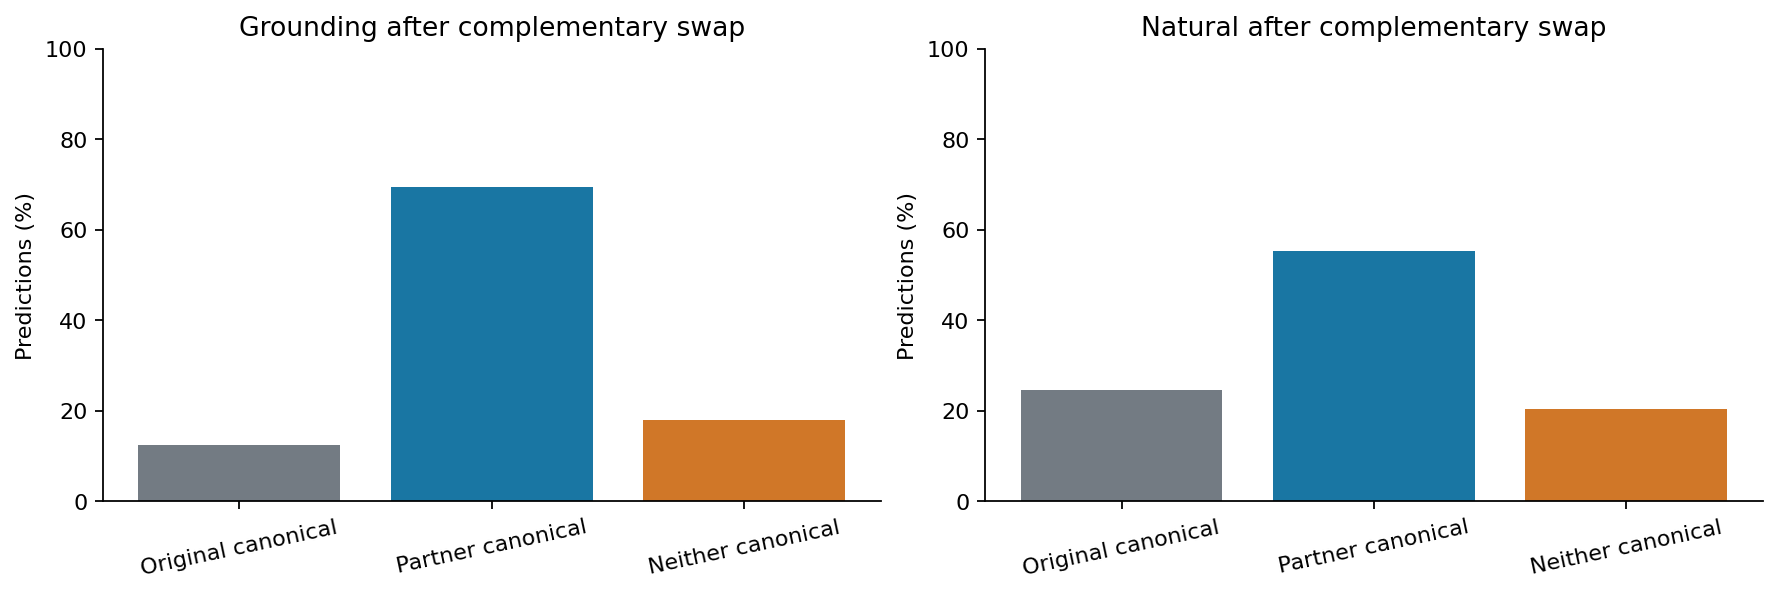

suite,questions,prediction_changed_rate,swap_original_canonical_rate,swap_partner_canonical_rate,swap_neither_canonical_rate,changed_and_partner_rate
grounding,128,0.796875,0.125,0.6953125,0.1796875,0.6015625
natural,192,0.4791666666666667,0.24479166666666666,0.5520833333333334,0.203125,0.328125



In [7]:
display(Image(filename=str(TASK2 / 'figures/swap_answer_behavior.png')))
print((TASK2 / 'analysis/swap_behavior.csv').read_text())

## Aligned complementary-image examples

Five pairs were fixed before predictions: the first sorted pair per question type, excluding grounding pairs flagged in the pre-training annotation review. Both original images share the same question. Each panel shows original references and responses under all four conditions. This is a stated illustrative selection, not a random sample of successes. All required evaluation examples remain in primary scoring.

First pair in sorted pair-ID order per question type, excluding grounding pairs flagged in the pre-training contact-sheet review. Fixed before predictions.


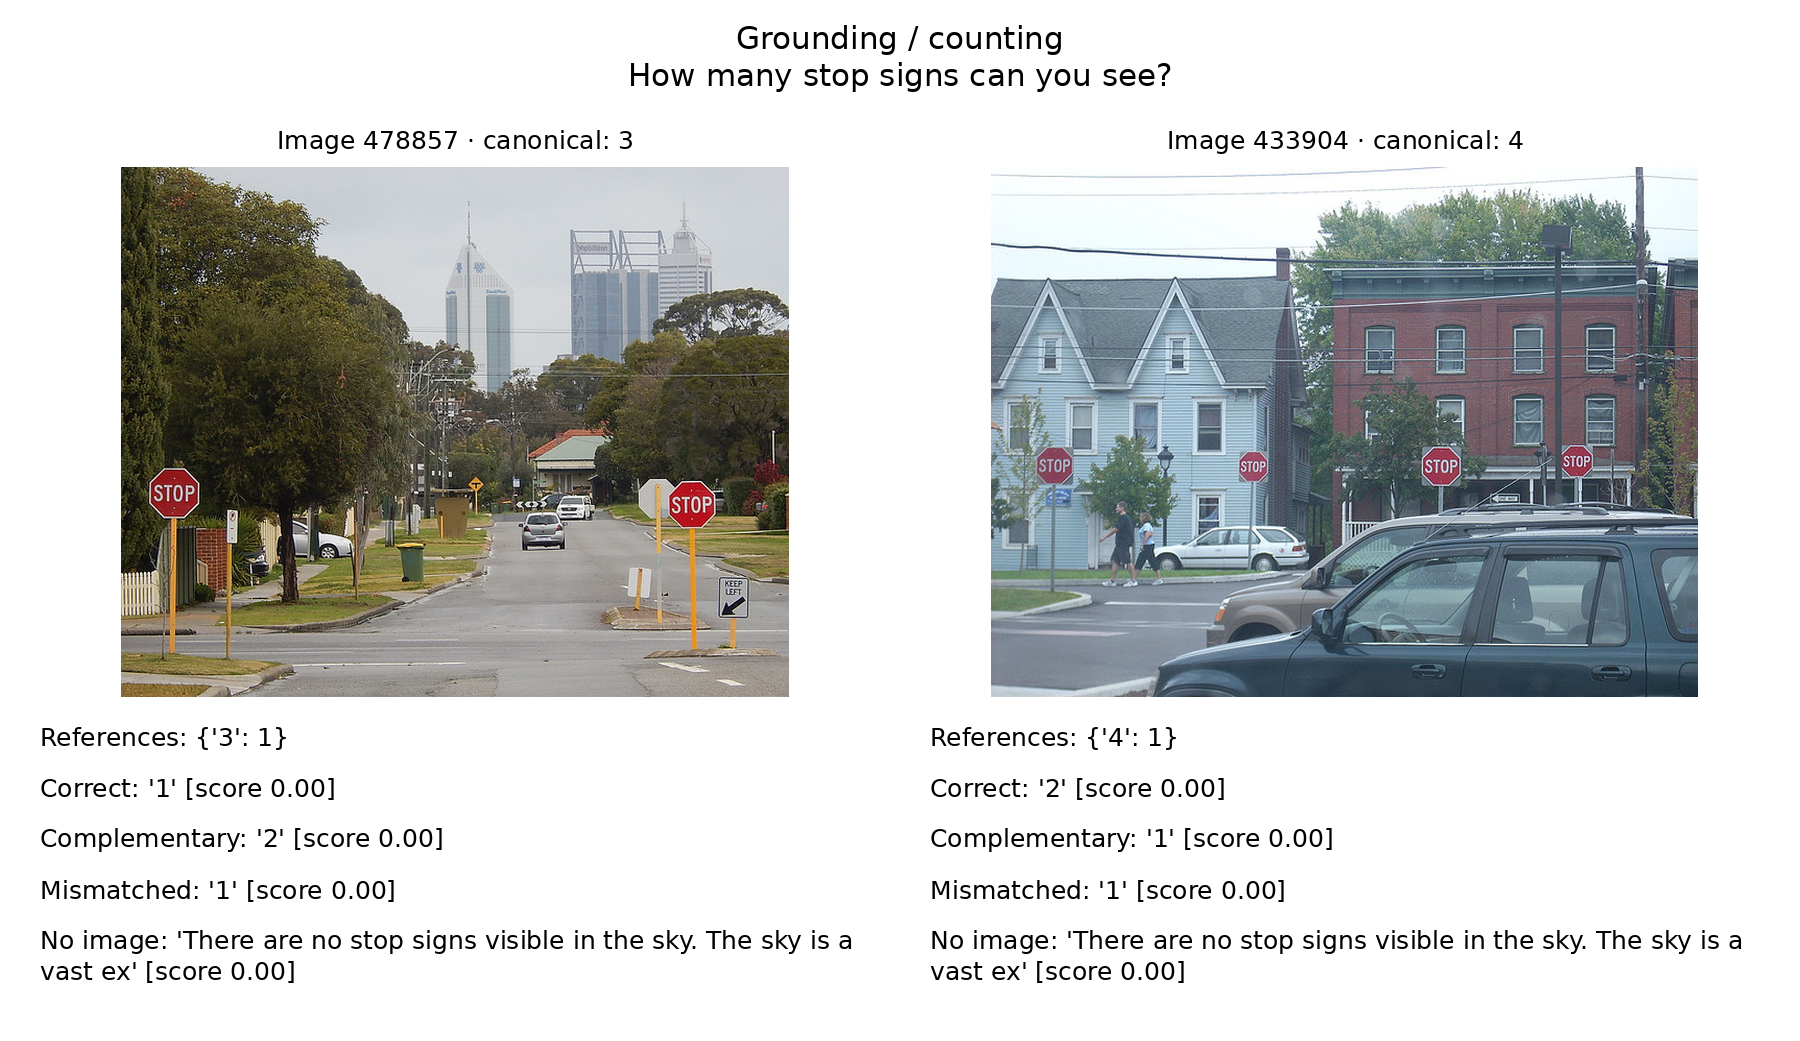

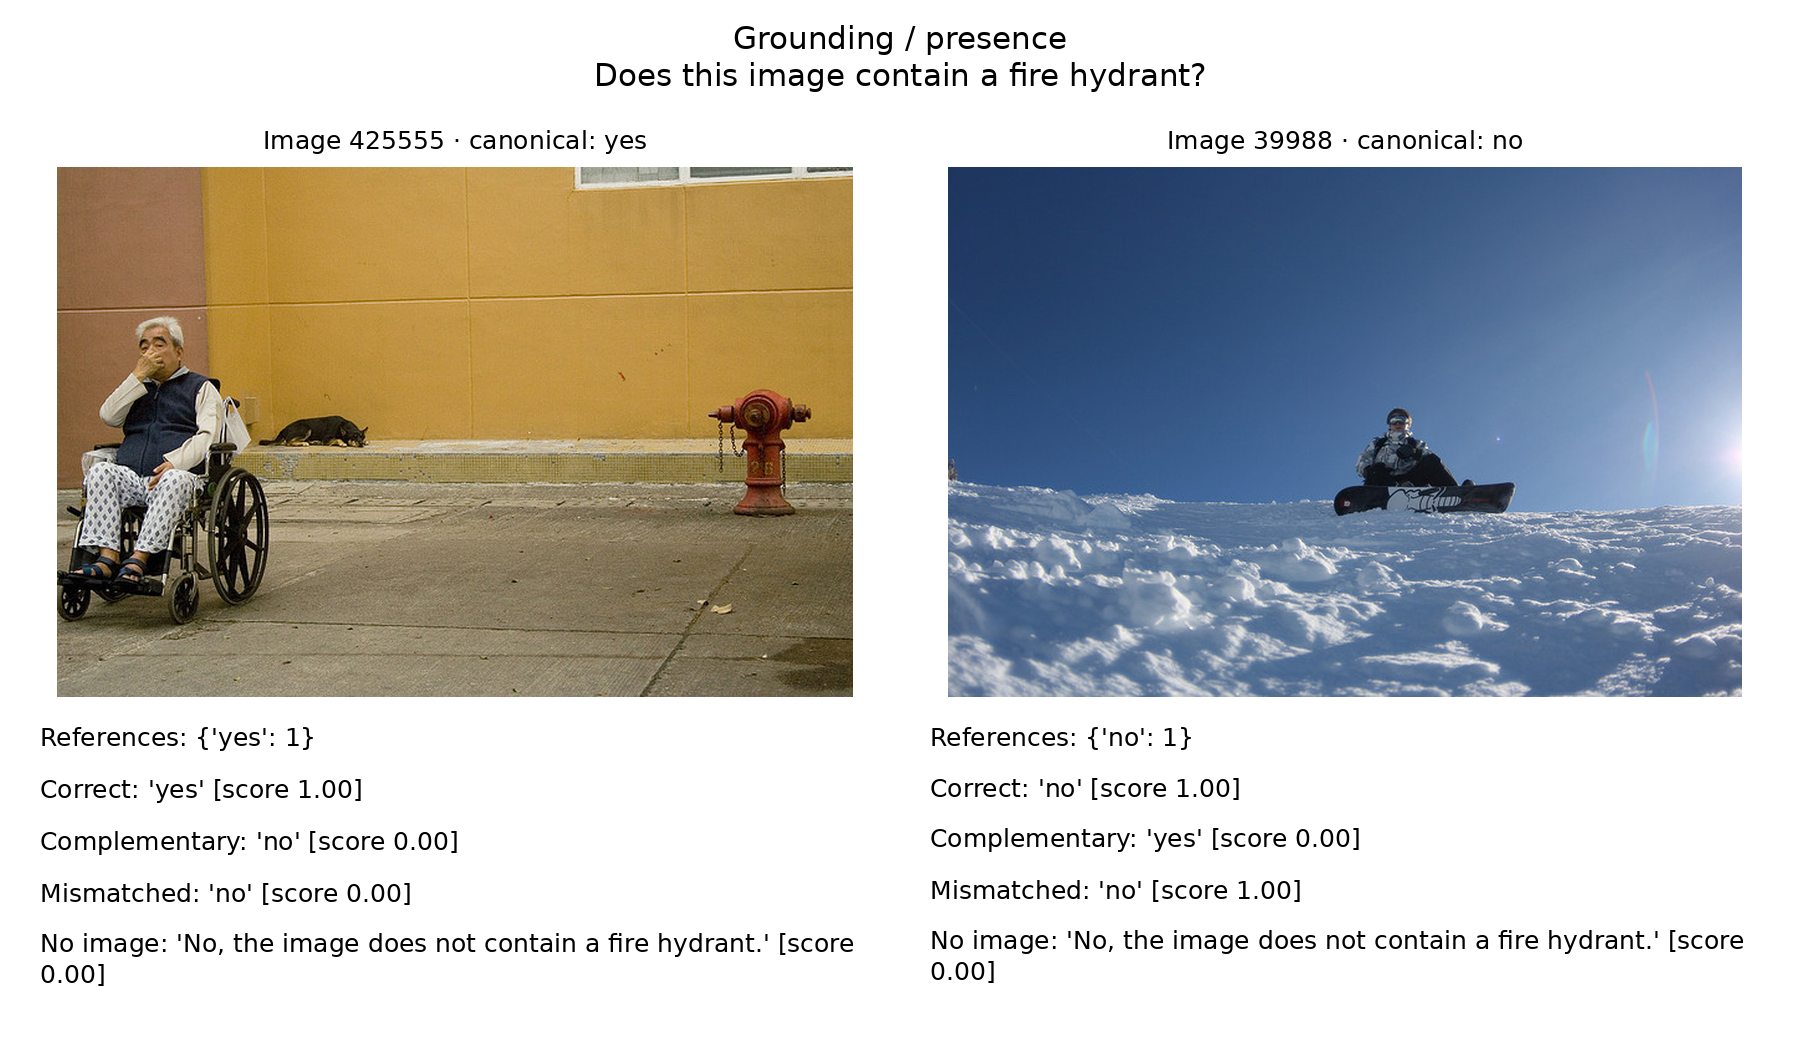

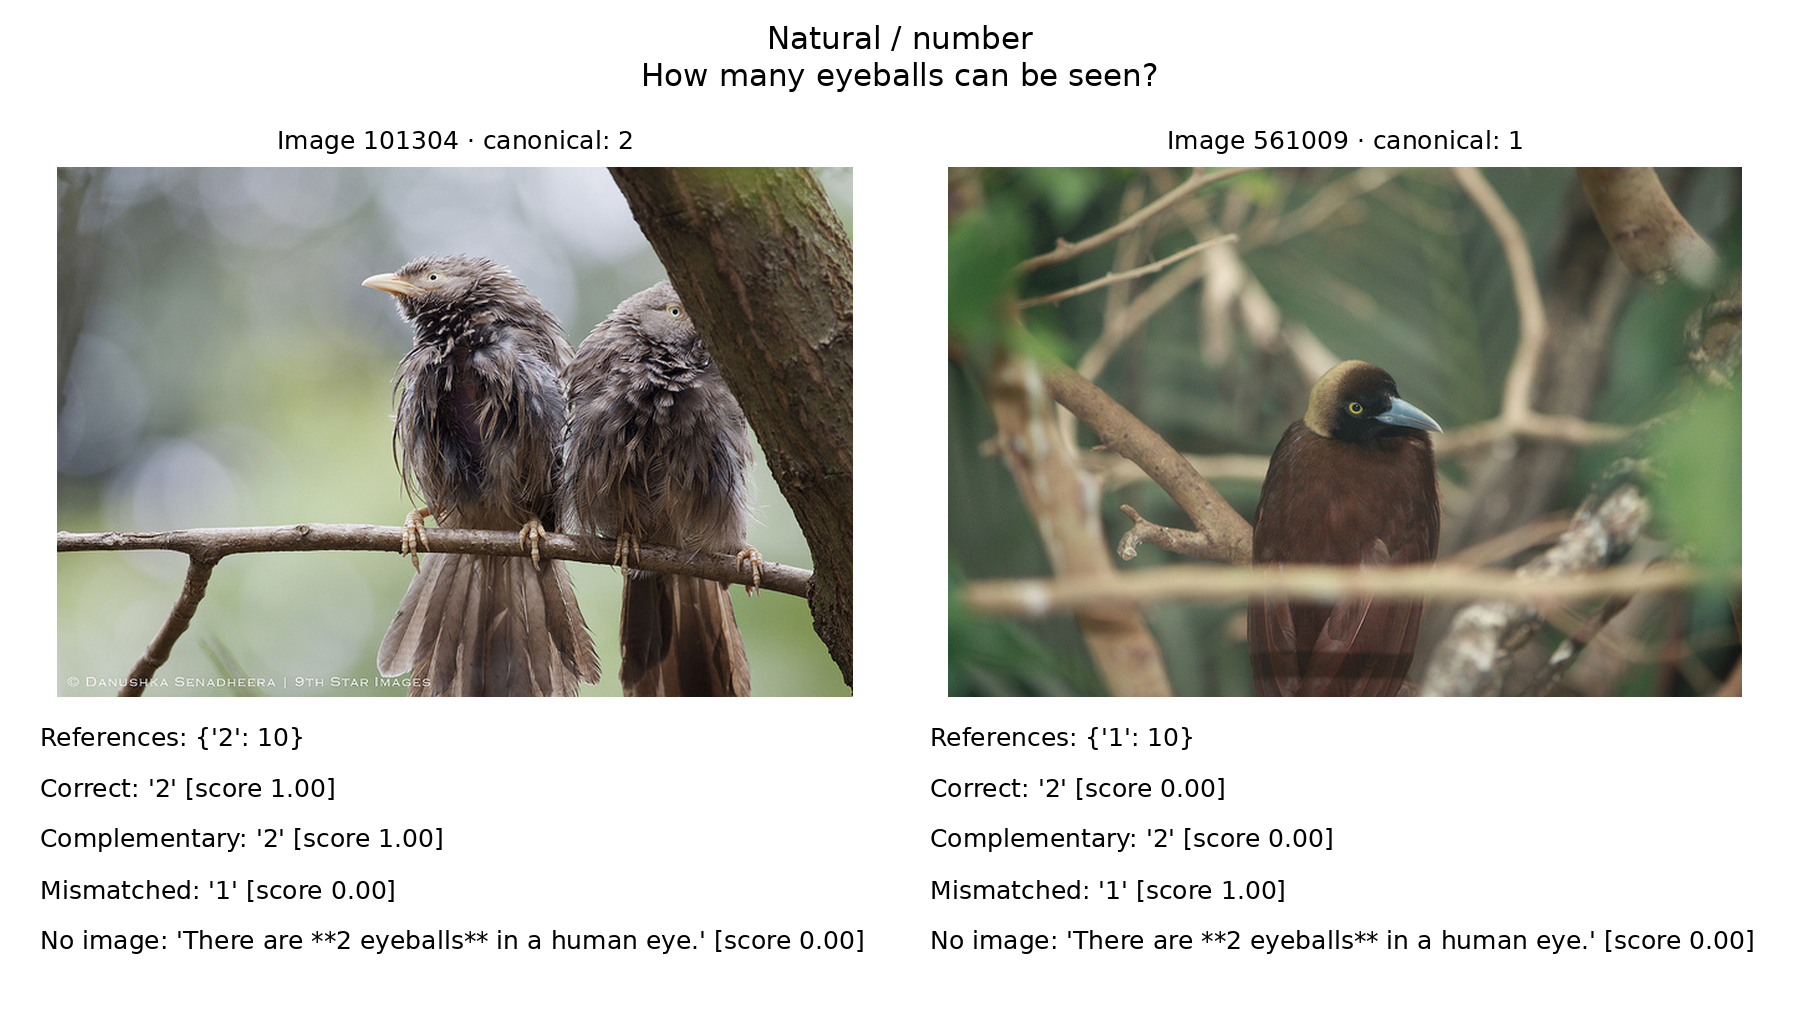

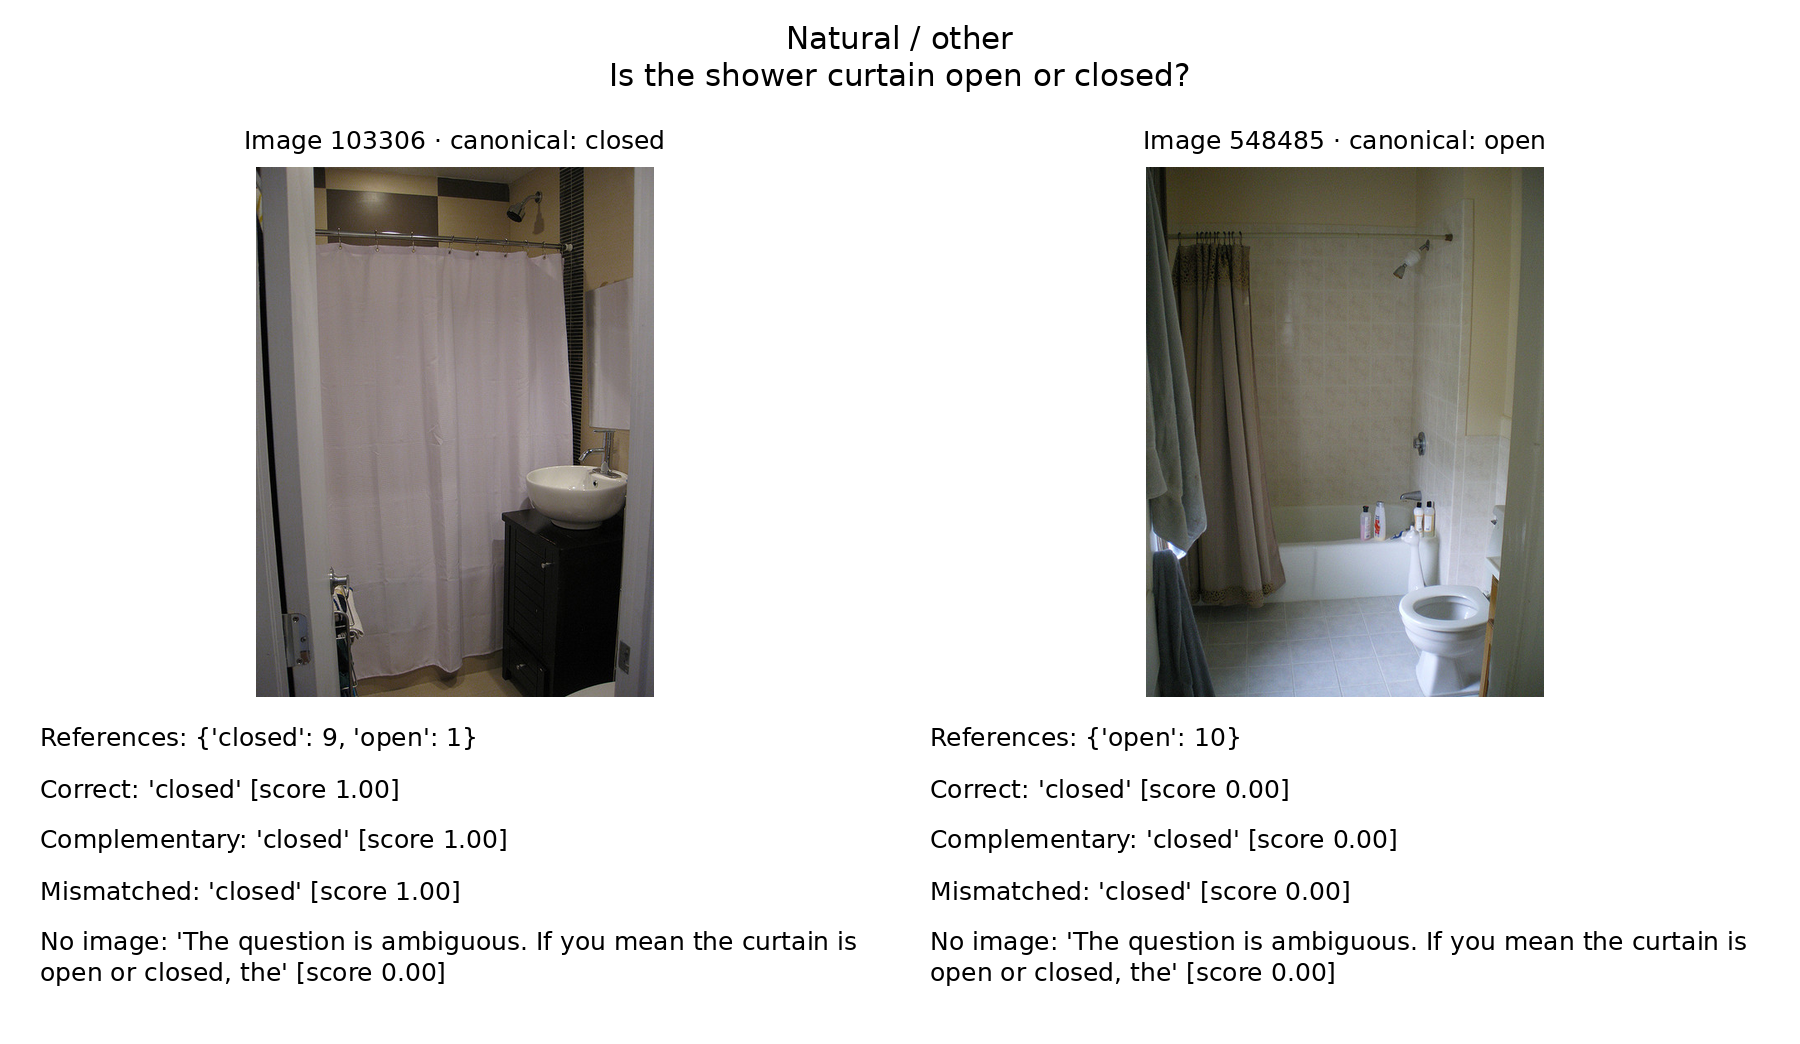

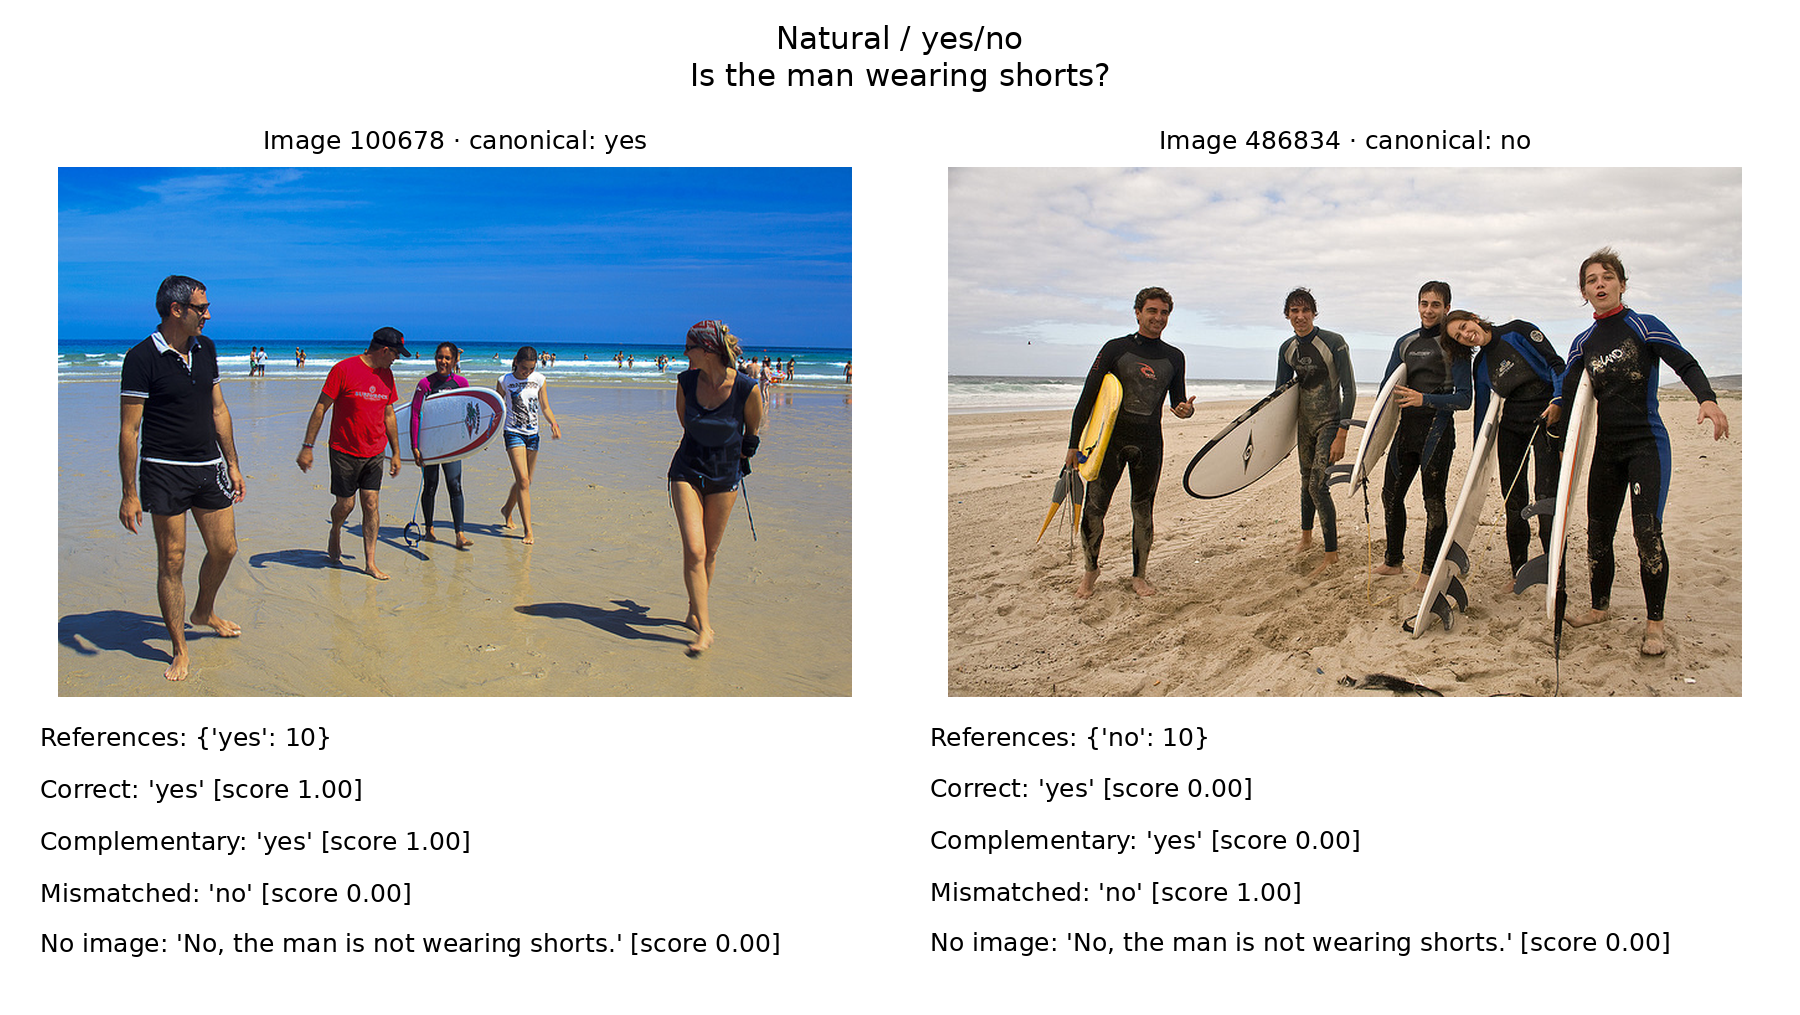

In [8]:
qual = json.loads((TASK2 / 'analysis/qualitative_status.json').read_text())
print(qual['selection_rule'])
for relative in qual['pages']:
    path = TASK2 / relative
    assert path.is_file(), f'Missing qualitative panel: {path}'
    display(Image(filename=str(path)))

## Resources

Resource timing scopes are separated below. Training time is the sum of update calls, including overflow retries; it excludes development evaluation, loading and checkpoint writes. Generation timing is amortized over batches. Allocated and reserved GPU memory are different measures. The feature benchmark selected batch 128; training and final-generation batches follow the prescribed recipe.

In [9]:
display(Markdown((TASK2 / 'analysis/resources.md').read_text()))

# Recorded resources

| phase | updates | presentations | trainable_parameters | measured_seconds | peak_allocated_GiB | peak_reserved_GiB | timing_scope |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Feature caching | 0 | 6528 | 0 | 150.64900136299997 | 0.6581196784973145 |  | Feature-cache process session; staging, preprocessing, forward and persistence. Excludes smoke and main training. |
| Stage 1 | 2250 | 36000 | 1837056 | 1100.8001436249958 | 3.114654064178467 | 10.375 | Sum of update calls, including overflow retries; excludes development, checkpoint saves and model loading. |
| Stage 2 | 1500 | 24000 | 6424576 | 1178.7881800110022 | 3.093252658843994 | 10.44921875 | Sum of update calls, including overflow retries; excludes development, checkpoint saves and model loading. |
| Stage 3 | 750 | 12000 | 6424576 | 594.2121995770053 | 3.039240837097168 | 10.44921875 | Sum of update calls, including overflow retries; excludes development, checkpoint saves and model loading. |
| Final evaluation | 0 | 1280 | 0 | 71.06560166300005 | 1.8591012954711914 |  | Final evaluation session, including reference NLL, generation, bootstrap and output writes; excludes model loading. |

Total main-update time: 2873.80 s. Development evaluations: 39.33 s. Recovery-state writes: 6.65 s. Generation only (all 1280 outputs): 58.94 s. The logs do not record one complete queue wall-clock duration.

Feature forwards alone took 2.413 s; this is not the feature-caching wall time. Five initial AMP overflow attempts were retried on the same sampled batch before any successful update. Frozen weights and inference-only arrays are excluded from trainable counts.


## Interpretation and limitations

In [10]:
display(Markdown((TASK2 / 'analysis/RESULTS.md').read_text()))

# Task 2 results and interpretation

The final Stage 3 checkpoint was evaluated on fixed, image-disjoint local subsets. No final-test score selected the checkpoint. Grounding uses normalized exact match and natural VQA uses the ten-answer soft consensus score. Intervals resample complete pairs 4000 times, reusing pair indices across image conditions.

## Curriculum

Caption development loss decreased from 5.8840 before training to 2.5623 after caption alignment and 2.5400 after Stage 3. This is reference-likelihood evidence for caption alignment; no caption-generation evaluation was performed. Grounding development swap penalties were near zero after Stage 1 (0.0179), reached 3.1992 after Stage 2, and ended at 2.1299 after natural VQA specialization. Natural VQA penalties grew from 0.1334 after Stage 1 to 1.1892 after Stage 2 and ended at 1.1419. Visual instruction training introduced substantially stronger image-conditioned answer likelihoods. Later natural specialization did not improve every development measure monotonically. Training losses across stages mix different target lengths and tasks, so their absolute levels are not directly comparable.

## Final accuracy and grounding

Grounding correct-image exact match was 69.53 [60.94, 77.34]%; complementary swaps scored 12.50 [7.03, 18.75]%. The paired advantage was 57.03 [44.53, 68.75] percentage points. Presence was easier than counting: 87.50% versus 51.56%.

Natural VQA correct-image soft accuracy was 58.96 [52.45, 65.42]%; complementary swaps scored 28.70 [23.28, 34.38]%. Its paired advantage was 30.26 [21.30, 39.48] percentage points. Correct-image scores were 75.83% yes/no, 44.79% number, and 51.53% other.

## What the controls measure

Correct images improve both generated accuracy and teacher-forced original-reference likelihood. Complementary swaps preserve the question and visual-token count, making their paired comparison stronger evidence of image use than the no-image contrast alone. Mismatched inputs use an unrelated image from the same suite and keep original references fixed. Swap correctness is always scored against the original image references; partner-answer following is reported separately.

For grounding, 79.69% of answers changed after swapping. Among all swapped predictions, 69.53% matched the partner canonical answer, 12.50% matched the original canonical answer, and 17.97% matched neither. These are canonical-string diagnostics; natural VQA soft credit can differ.

For natural, 47.92% of answers changed after swapping. Among all swapped predictions, 55.21% matched the partner canonical answer, 24.48% matched the original canonical answer, and 20.31% matched neither. These are canonical-string diagnostics; natural VQA soft credit can differ.

Both no-image suites scored zero under the required exact/soft answer scoring, with no empty outputs. This does not mean the model produced no relevant words: many responses became explanatory sentences rather than canonical short answers. Grounding had 50/128 capped outputs and natural VQA had 114/192. Omitting 196 visual tokens also shortens the prefix and shifts the model away from its trained image-conditioned input format. The zero score therefore combines lost visual information with format and distribution changes; it is not a clean estimate of language-only knowledge. No substring extraction or post-hoc answer rewriting was applied.

## Pair-level and qualitative evidence

Pair accuracy requires both responses to match their original canonical targets. Identical-answer rates count equal normalized responses, including empty responses if present. The complete tables report both metrics alongside reference NLL and generation time. Five illustrative pairs were fixed before predictions: the first sorted pair per question type, excluding grounding pairs flagged in the pre-training review. They illustrate behavior and are not a random estimate of success frequency. Consult the aligned original-image panels and raw responses rather than inferring visual correctness from answer changes alone.

In the selected fire-hydrant presence pair, correct-image outputs are yes/no and complementary outputs reverse to no/yes, matching the partner-image answers. In the stop-sign counting pair, the model predicts 1/2 against annotation targets 3/4; swapping reverses its predictions to 2/1 but neither original target is recovered. This is image sensitivity without accurate counting.

The selected natural pairs show failures that aggregate accuracy alone hides. The model answers 2 for both bird-eye images (targets 2/1), closed for both shower curtains (closed/open), and yes for both shorts questions (yes/no). These answers remain unchanged under complementary swaps, so each pair has one canonical hit but zero pair accuracy. The no-image bird response contains the numeral 2 inside a full sentence and receives zero under the required whole-answer scoring; this illustrates the format limitation without changing the scorer.

## Limits

- Checkpoint tensor files, cached feature arrays, original model weights and image TARs are not included in this review export; their recorded hashes are retained but their bytes were not re-audited here.
- Raw tokenized examples and calibration token lists are not in the review export. The prior CPU and GPU preflight records and frozen input hashes are available.
- The 30 annotation-ambiguity flags came from assistant contact-sheet inspection before training, not independent human adjudication; primary scores retain every fixed example.
- Single seed and selected high-consensus subsets; bootstrap intervals quantify pair sampling variation, not training-seed uncertainty or full-benchmark performance.
- Annotation-derived absence means no recorded object annotation, and counts depend on COCO object instances, occlusion and category conventions. Thirty of 88 reviewed development/test grounding pairs were flagged for possible ambiguity; this is not evidence that all 30 labels are wrong. All examples remain in primary scores.
- A 16-new-token cap can affect verbose outputs, particularly the no-image condition. Timing reflects this A100 run, batch size and implementation; per-answer timings are amortized over generation batches.
- Only the required 196-token recipe was run; the optional 49-token experiment was not performed.
- These notes are an analysis draft for student review and the combined report, not an independently adjudicated annotation study.


## Optional reproduction on the existing prepared Drive experiment

The recorded main run is complete. Leave the following switch `False` for CPU report viewing. For a new run, first reproduce CPU data/image preparation using the scripts and pinned assets described in the README. The GPU command below uses the existing prepared Drive experiment and verifies its frozen identities. Completed phases are skipped and interrupted training resumes from its latest marked recovery state. Reproduction requires the recorded CUDA/package environment. It does not redownload missing assets automatically.

Only enable this cell after selecting the appropriate GPU runtime. The runtime is released in `finally` once an enabled queue finishes or fails.

In [11]:
RUN_GPU_QUEUE = False
if RUN_GPU_QUEUE:
    from google.colab import runtime
    EXPERIMENT = Path('/content/drive/MyDrive/ATML/PA3/task2')
    assert (EXPERIMENT / 'data/tokenized_examples.json').is_file()
    try:
        subprocess.run([
            sys.executable, str(EXPERIMENT / 'code/task2_run.py'),
            '--task-dir', str(EXPERIMENT), '--run-all',
        ], check=True)
    finally:
        runtime.unassign()
else:
    print('GPU queue disabled. Saved-result analysis is complete.')


GPU queue disabled. Saved-result analysis is complete.
